<a href="https://colab.research.google.com/github/whoiswasd/mineria/blob/main/Actividad-2_8/Actividad_2_8_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.7 - Regresión lineal

**Asignatura:** Minería de Datos

**Nombre Estudiante:**  Pohla Lopez

## Objetivo
Aplicar modelos de regresión lineal simple y múltiple utilizando Python y scikit-learn, evaluando su rendimiento mediante R², MAE y RMSE.

Se trabajará con tres datasets para analizar relaciones entre variables, interpretar coeficientes y reconocer problemas como fuga de datos, multicolinealidad y heterogeneidad.

**Bibliotecas**


In [3]:
import os
from pathlib import Path

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import userdata
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")

**configuración de Kaggle**

In [4]:
token = userdata.get("KAGGLE_API_TOKEN")

if token:
    os.environ["KAGGLE_API_TOKEN"] = token

# Bloque 1. Regresión lineal simple – Breast Cancer

En este bloque se utilizará el dataset Breast Cancer Wisconsin para estudiar la relación entre distintas mediciones de células.

Se entrenarán dos modelos:

- Modelo 1: radius_mean para predecir perimeter_mean.
- Modelo 2: radius_mean para predecir area_mean.

Ambos modelos se evaluarán utilizando datos de entrenamiento y prueba.

**Carga del dataset**


In [5]:
carpeta = Path(
    kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
)

print("Archivos disponibles:")

for archivo in carpeta.rglob("*"):
    if archivo.is_file():
        print(archivo.name)

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Archivos disponibles:
data.csv


In [6]:
df = pd.read_csv(carpeta / "data.csv")

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Exploración de datos**

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
print("Valores nulos:")
display(df.isnull().sum())

print("Estadísticas descriptivas:")
display(df.describe())

Valores nulos:


,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


Estadísticas descriptivas:


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


**Limpieza**

In [9]:
df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

print("Dimensiones después de la limpieza:", df.shape)

Dimensiones después de la limpieza: (569, 31)


Se eliminó la columna `id` porque solo identifica los registros y no representa una medición útil para la regresión.

También se eliminó `Unnamed: 32`, si estaba presente, porque no contiene información relevante.

La columna `diagnosis` no se utilizará como predictor, ya que corresponde a una clasificación y el objetivo de este bloque es trabajar con mediciones numéricas.

**Análisis exploratorio (EDA)**

**histogramas**

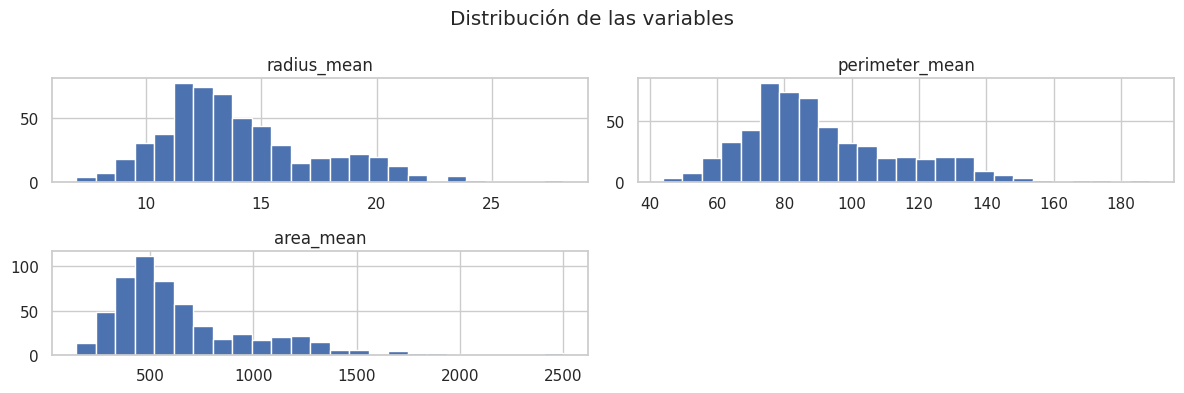

In [10]:
columnas = ["radius_mean", "perimeter_mean", "area_mean"]

df[columnas].hist(figsize=(12, 4), bins=25)
plt.suptitle("Distribución de las variables")
plt.tight_layout()
plt.show()

**box-plots**

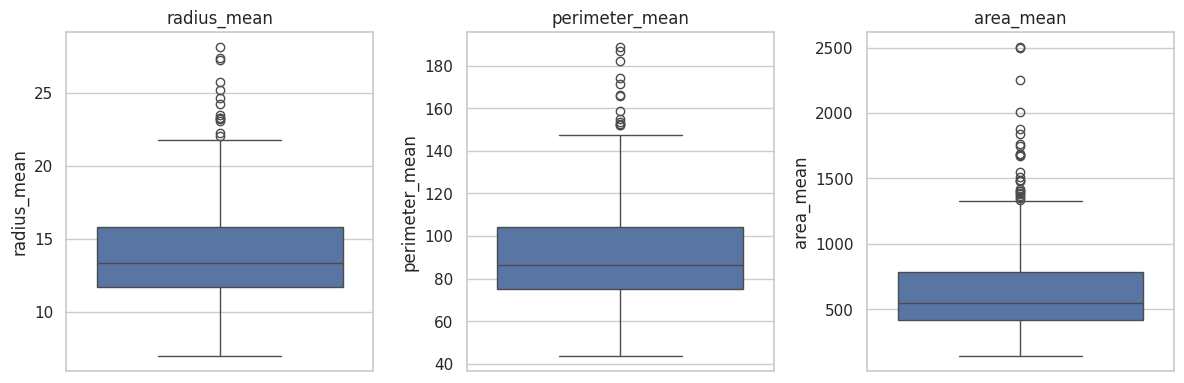

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, columna in zip(axes, columnas):
    sns.boxplot(y=df[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

**correlaciones**

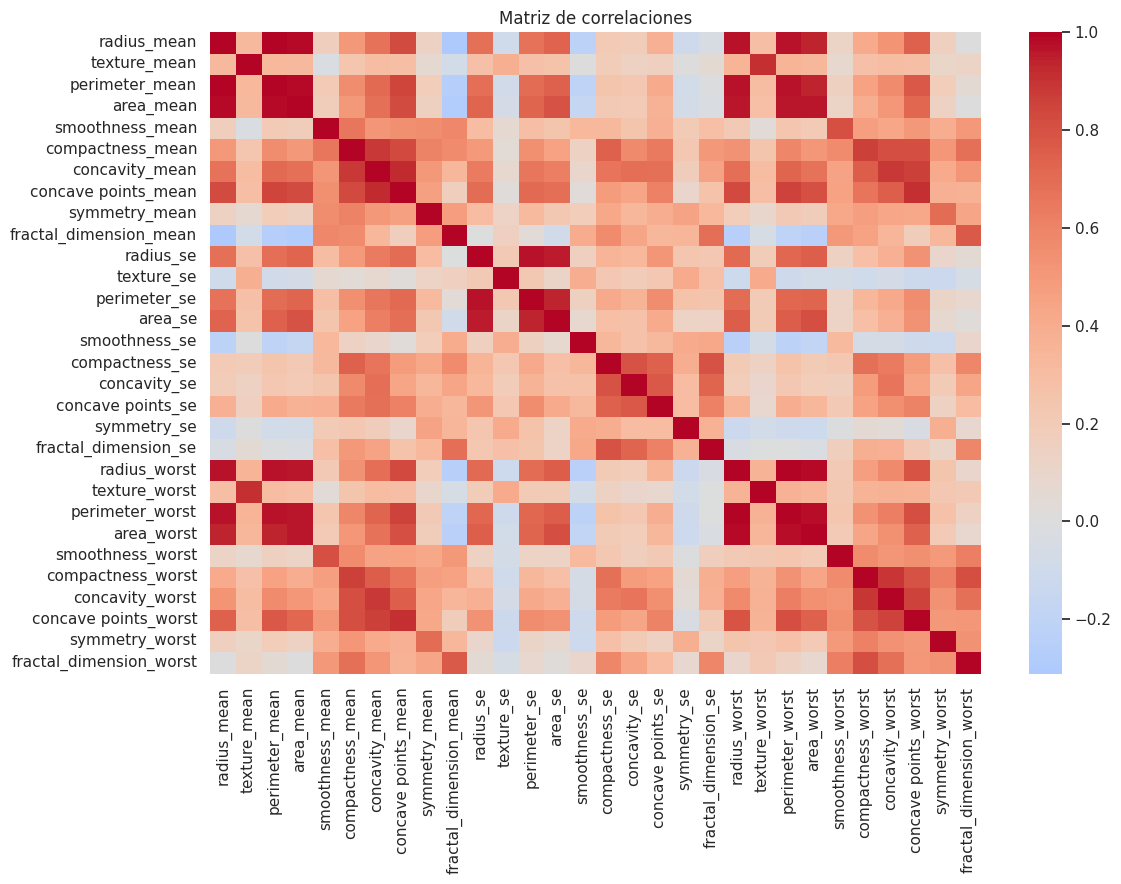

,perimeter_mean,area_mean
radius_mean,0.997855,0.987357


In [12]:
correlaciones = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlaciones,
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()

display(
    correlaciones.loc[
        ["radius_mean"],
        ["perimeter_mean", "area_mean"]
    ]
)

Se analizaron las distribuciones, los posibles valores atípicos y las correlaciones entre las mediciones.

La correlación permite identificar qué tan fuerte es la relación lineal entre el radio y las variables que se desean predecir.

Se utilizará `radius_mean` como predictor para comparar su relación con el perímetro y el área.

**Modelo 1: predicción del perímetro**

In [13]:
X1 = df[["radius_mean"]]
y1 = df["perimeter_mean"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

modelo1 = LinearRegression()
modelo1.fit(X1_train, y1_train)

pred1 = modelo1.predict(X1_test)

print("Pendiente:", modelo1.coef_[0])
print("Intercepto:", modelo1.intercept_)

Pendiente: 6.863974682090254
Intercepto: -5.020848584173891


**Métricas**

In [14]:
r2_1 = r2_score(y1_test, pred1)
mae_1 = mean_absolute_error(y1_test, pred1)
rmse_1 = np.sqrt(mean_squared_error(y1_test, pred1))

print("R²:", round(r2_1, 4))
print("MAE:", round(mae_1, 4))
print("RMSE:", round(rmse_1, 4))

R²: 0.9957
MAE: 1.0424
RMSE: 1.5834


**recta de regresión**

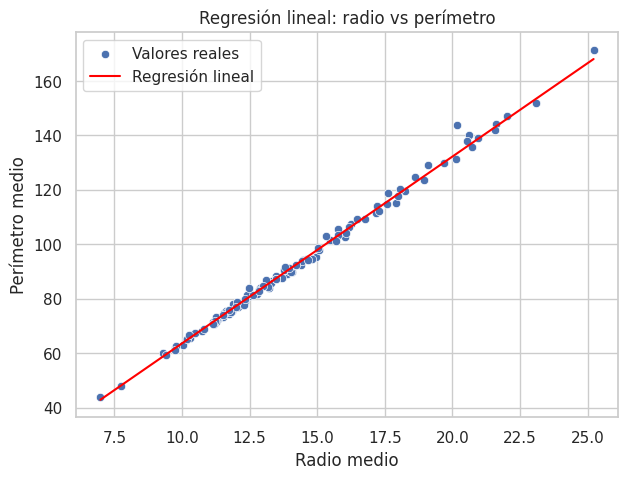

In [15]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X1_test["radius_mean"],
    y=y1_test,
    label="Valores reales"
)

orden = np.argsort(X1_test["radius_mean"].to_numpy())

plt.plot(
    X1_test["radius_mean"].to_numpy()[orden],
    pred1[orden],
    color="red",
    label="Regresión lineal"
)

plt.xlabel("Radio medio")
plt.ylabel("Perímetro medio")
plt.title("Regresión lineal: radio vs perímetro")
plt.legend()
plt.show()

**Residuos**

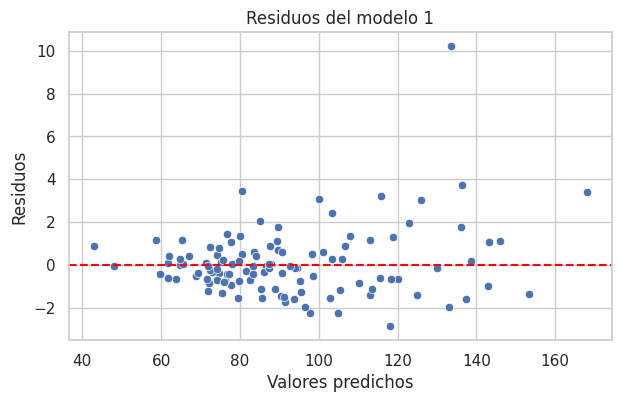

In [16]:
residuos1 = y1_test - pred1

plt.figure(figsize=(7, 4))

sns.scatterplot(x=pred1, y=residuos1)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos del modelo 1")
plt.show()

La pendiente indica cuánto aumenta el perímetro medio por cada unidad adicional del radio medio, según el modelo.

El intercepto representa el perímetro estimado cuando el radio es cero, aunque este valor no necesariamente tiene una interpretación física útil.

El R² muestra qué proporción de la variación del perímetro explica el modelo. El MAE y el RMSE indican el tamaño de los errores de predicción, en las mismas unidades del perímetro.

**Modelo 2: predicción del área**

In [17]:
X2 = df[["radius_mean"]]
y2 = df["area_mean"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

modelo2 = LinearRegression()
modelo2.fit(X2_train, y2_train)

pred2 = modelo2.predict(X2_test)

print("Pendiente:", modelo2.coef_[0])
print("Intercepto:", modelo2.intercept_)

Pendiente: 99.04084012256651
Intercepto: -743.8448648515803


**Métricas**

In [18]:
r2_2 = r2_score(y2_test, pred2)
mae_2 = mean_absolute_error(y2_test, pred2)
rmse_2 = np.sqrt(mean_squared_error(y2_test, pred2))

print("R²:", round(r2_2, 4))
print("MAE:", round(mae_2, 4))
print("RMSE:", round(rmse_2, 4))

R²: 0.9812
MAE: 34.9748
RMSE: 46.5776


**Recta**

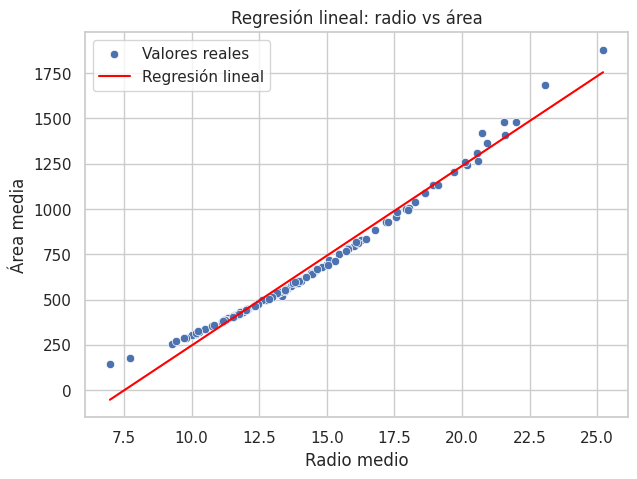

In [19]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X2_test["radius_mean"],
    y=y2_test,
    label="Valores reales"
)

orden = np.argsort(X2_test["radius_mean"].to_numpy())

plt.plot(
    X2_test["radius_mean"].to_numpy()[orden],
    pred2[orden],
    color="red",
    label="Regresión lineal"
)

plt.xlabel("Radio medio")
plt.ylabel("Área media")
plt.title("Regresión lineal: radio vs área")
plt.legend()
plt.show()

**Residuos**

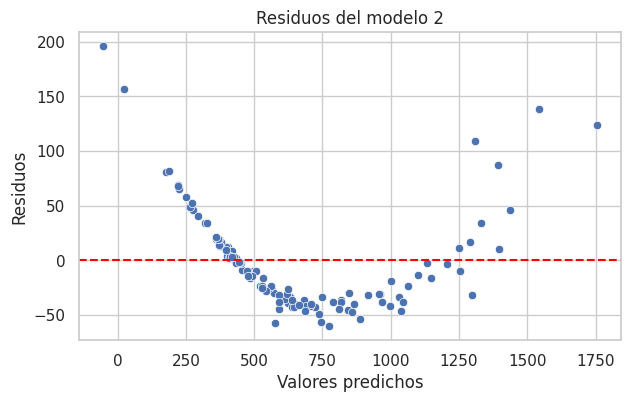

In [20]:
residuos2 = y2_test - pred2

plt.figure(figsize=(7, 4))

sns.scatterplot(x=pred2, y=residuos2)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos del modelo 2")
plt.show()

**Comparación de los modelos**

In [21]:
comparacion = pd.DataFrame({
    "Modelo": ["Perímetro", "Área"],
    "R²": [r2_1, r2_2],
    "MAE": [mae_1, mae_2],
    "RMSE": [rmse_1, rmse_2]
})

display(comparacion.round(4))

,Modelo,R²,MAE,RMSE
0,Perímetro,0.9957,1.0424,1.5834
1,Área,0.9812,34.9748,46.5776


Los dos modelos utilizan el mismo predictor, pero intentan estimar variables diferentes.

Para comparar su desempeño se debe considerar tanto el R² como la distribución de los residuos. No es adecuado comparar directamente los valores absolutos de MAE y RMSE entre perímetro y área, porque tienen unidades diferentes.

**¿Un R² alto garantiza que una recta sea adecuada?**

No. Un R² alto indica que el modelo explica una proporción importante de la variabilidad de la variable objetivo, pero no garantiza que la relación sea verdaderamente lineal.

Si los residuos muestran una curva o algún patrón sistemático, significa que la recta no está representando correctamente toda la relación entre las variables.

# Bloque 2. Regresión lineal múltiple – FIFA 19

En este bloque se utilizarán las características de los jugadores de FIFA 19 para predecir su valoración general (`Overall`).

Se analizarán las correlaciones entre variables, la fuga de datos, la multicolinealidad y las diferencias de rendimiento entre grupos de jugadores.

**Carga e inspección**

In [27]:
carpeta_fifa = Path(
    kagglehub.dataset_download(
        "javagarm/fifa-19-complete-player-dataset"
    )
)

print("Archivos disponibles:")

for archivo in carpeta_fifa.rglob("*"):
    if archivo.is_file():
        print(archivo.name)

Using Colab cache for faster access to the 'fifa-19-complete-player-dataset' dataset.
Archivos disponibles:
kl.csv


In [29]:
df_fifa = pd.read_csv(
    carpeta_fifa / "kl.csv",
    encoding="cp1252"
)

print("Dimensiones:", df_fifa.shape)
display(df_fifa.head())

Dimensiones: (18207, 89)


,Unnamed: 0,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,0,158023,L. Messi,31.0,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94.0,94,FC Barcelona,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,1,20801,Cristiano Ronaldo,33.0,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94.0,94,Juventus,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,2,190871,Neymar Jr,26.0,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92.0,93,Paris Saint-Germain,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,3,193080,De Gea,27.0,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91.0,93,Manchester United,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,4,192985,K. De Bruyne,27.0,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91.0,92,Manchester City,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [31]:
df_fifa.info()

print("Valores nulos:")
display(df_fifa.isnull().sum().sort_values(ascending=False).head(20))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 89 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                18207 non-null  int64  
 1   ID                        18207 non-null  int64  
 2   Name                      18207 non-null  object 
 3   Age                       18206 non-null  float64
 4   Photo                     18207 non-null  object 
 5   Nationality               18207 non-null  object 
 6   Flag                      18207 non-null  object 
 7   Overall                   18206 non-null  float64
 8   Potential                 18207 non-null  int64  
 9   Club                      17966 non-null  object 
 10  Club Logo                 18207 non-null  object 
 11  Value                     18207 non-null  object 
 12  Wage                      18207 non-null  object 
 13  Special                   18207 non-null  int64  
 14  Prefer

,0
Loaned From,16943
RWB,2085
RDM,2085
CDM,2085
LDM,2085
LWB,2085
CB,2085
LCB,2085
LB,2085
CM,2085


**Análisis exploratorio**

In [32]:
candidatas = [
    "Age", "Potential", "International Reputation",
    "Weak Foot", "Skill Moves", "Crossing",
    "Finishing", "ShortPassing", "Dribbling",
    "BallControl", "Reactions", "Stamina",
    "Strength", "SprintSpeed", "Acceleration",
    "LongShots"
]

columnas_fifa = ["Overall"] + candidatas

datos_fifa = df_fifa[columnas_fifa].copy()

display(datos_fifa.describe())

,Overall,Age,Potential,International Reputation,Weak Foot,Skill Moves,Crossing,Finishing,ShortPassing,Dribbling,BallControl,Reactions,Stamina,Strength,SprintSpeed,Acceleration,LongShots
count,18206.000000,18206.000000,18207.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000
mean,66.237449,25.122048,71.307299,1.113222,2.947299,2.361308,49.734181,45.550911,58.686712,55.371001,58.369459,61.836610,63.219946,65.311967,64.726967,64.614076,47.109973
std,6.907059,4.670022,6.136496,0.394031,0.660456,0.756164,18.364524,19.525820,14.699495,18.910371,16.686595,9.010464,15.894741,12.557000,14.649953,14.927780,19.260524
min,46.000000,16.000000,48.000000,1.000000,1.000000,1.000000,5.000000,2.000000,7.000000,4.000000,5.000000,21.000000,12.000000,17.000000,12.000000,12.000000,3.000000
25%,62.000000,21.000000,67.000000,1.000000,3.000000,2.000000,38.000000,30.000000,54.000000,49.000000,54.000000,56.000000,56.000000,58.000000,57.000000,57.000000,33.000000
50%,66.000000,25.000000,71.000000,1.000000,3.000000,2.000000,54.000000,49.000000,62.000000,61.000000,63.000000,62.000000,66.000000,67.000000,67.000000,67.000000,51.000000
75%,71.000000,28.000000,75.000000,1.000000,3.000000,3.000000,64.000000,62.000000,68.000000,68.000000,69.000000,68.000000,74.000000,74.000000,75.000000,75.000000,62.000000
max,94.000000,45.000000,95.000000,5.000000,5.000000,5.000000,93.000000,95.000000,93.000000,97.000000,96.000000,96.000000,96.000000,97.000000,96.000000,97.000000,94.000000


El dataset contiene 18.207 jugadores registrados, aunque algunas variables presentan valores faltantes. La valoración general (Overall) tiene un promedio de 66,24 puntos y la edad promedio es de 25 años.

Las características técnicas y físicas presentan diferentes rangos de valores, lo que permitirá analizar cuáles tienen mayor relación con la valoración general de los jugadores.

Para entrenar el modelo se utilizarán únicamente los registros completos de las variables seleccionadas.

**distribuciones**

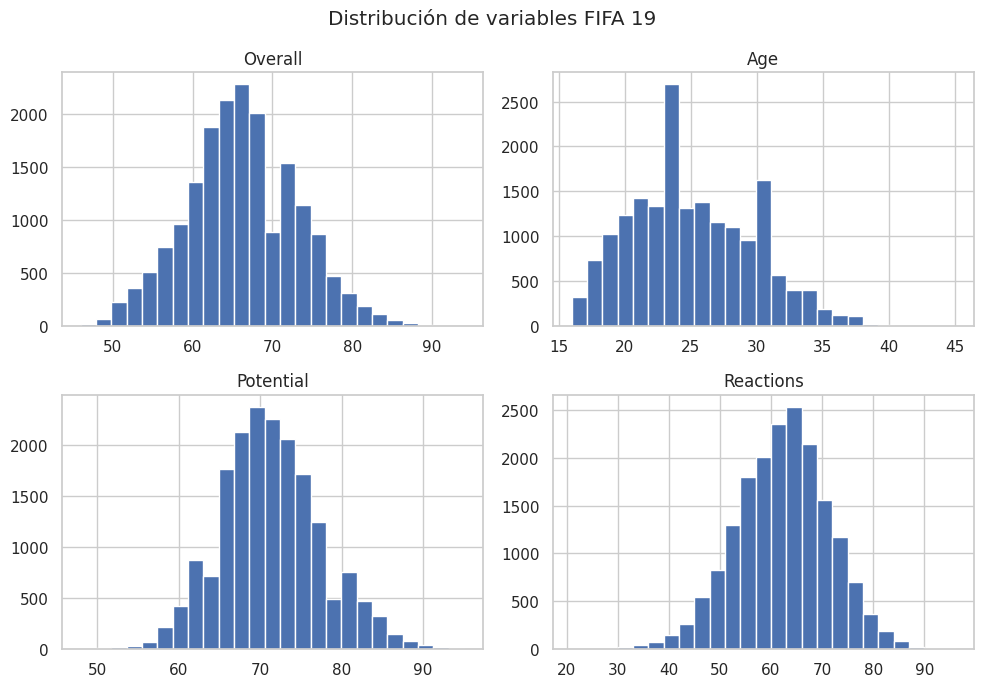

In [33]:
datos_fifa[
    ["Overall", "Age", "Potential", "Reactions"]
].hist(figsize=(10, 7), bins=25)

plt.suptitle("Distribución de variables FIFA 19")
plt.tight_layout()
plt.show()

**box-plots**

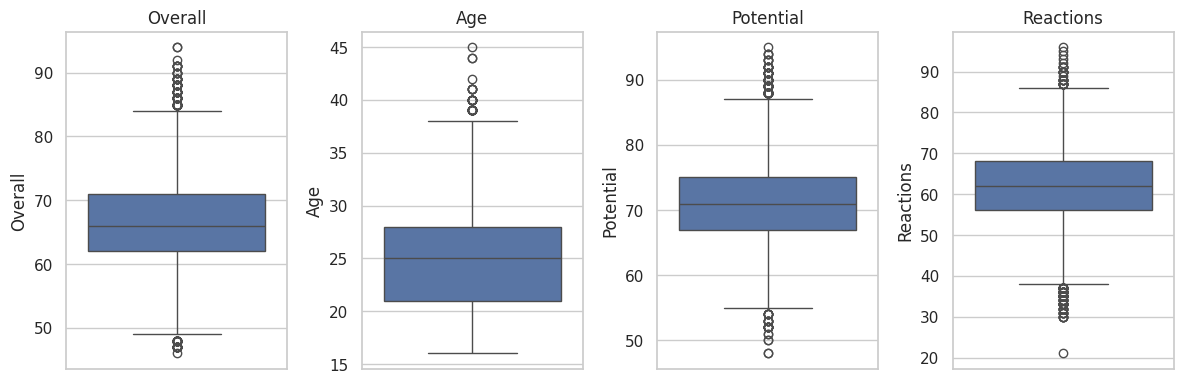

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for ax, columna in zip(
    axes, ["Overall", "Age", "Potential", "Reactions"]
):
    sns.boxplot(y=datos_fifa[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

**correlaciones con Overall**

,Correlación con Overall
Reactions,0.849987
Potential,0.660732
ShortPassing,0.503013
International Reputation,0.499087
BallControl,0.460847
Age,0.452486
LongShots,0.421313
Skill Moves,0.414950
Crossing,0.395472
Dribbling,0.372947


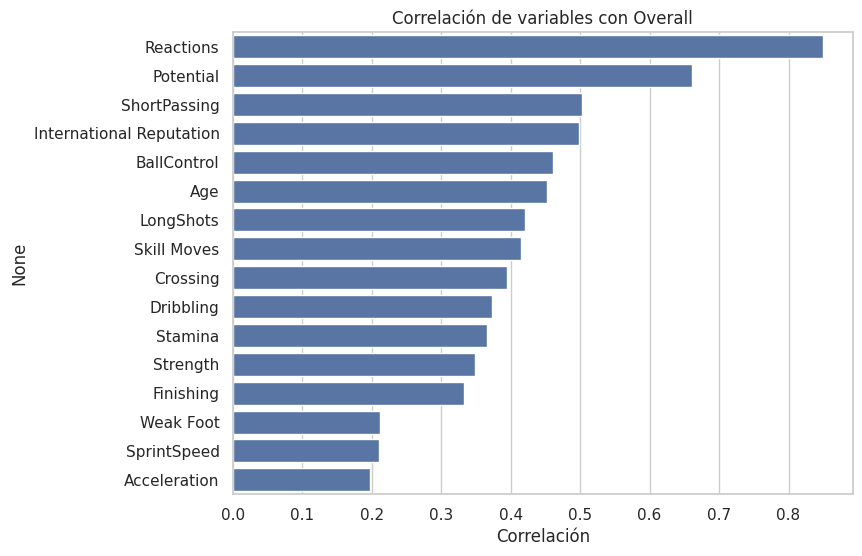

In [35]:
corr_overall = (
    datos_fifa.corr(numeric_only=True)["Overall"]
    .drop("Overall")
    .sort_values(ascending=False)
)

display(corr_overall.to_frame("Correlación con Overall"))

plt.figure(figsize=(8, 6))

sns.barplot(
    x=corr_overall.values,
    y=corr_overall.index
)

plt.title("Correlación de variables con Overall")
plt.xlabel("Correlación")
plt.show()

Se analizaron las características numéricas de los jugadores para identificar cuáles presentan mayor relación con la valoración general.

La correlación permite orientar la selección de predictores, pero una correlación alta no significa necesariamente que una variable sea apropiada.

También se debe revisar si las variables estarían disponibles antes de conocer la valoración que se quiere predecir.

**Selección de predictores y data leakage**

In [36]:
predictores = [
    "Age", "Weak Foot", "Skill Moves",
    "Crossing", "Finishing", "ShortPassing",
    "Dribbling", "BallControl", "Stamina",
    "Strength", "SprintSpeed", "Acceleration",
    "LongShots"
]

datos_modelo = df_fifa[
    predictores + ["Overall", "Position"]
].dropna().copy()

print("Registros disponibles:", len(datos_modelo))
print("Predictores seleccionados:", len(predictores))

Registros disponibles: 18145
Predictores seleccionados: 13


Se seleccionaron características relacionadas con la edad, la habilidad técnica y las capacidades físicas de los jugadores.

Se excluyó `Potential` porque representa una valoración estimada del jugador y podría incorporar información muy cercana al proceso de cálculo de `Overall`.

También se excluyeron `Value` y `Wage`, porque son variables económicas que pueden depender de la valoración del jugador.

Se mantuvieron atributos como `Finishing`, `Dribbling`, `Stamina` y `Strength`, considerando que representan características individuales del jugador. Sin embargo, si estas puntuaciones se calculan conjuntamente con `Overall`, podrían compartir información y limitar la validez del modelo para una predicción real.

**Multicolinealidad**

**matriz de correlación**

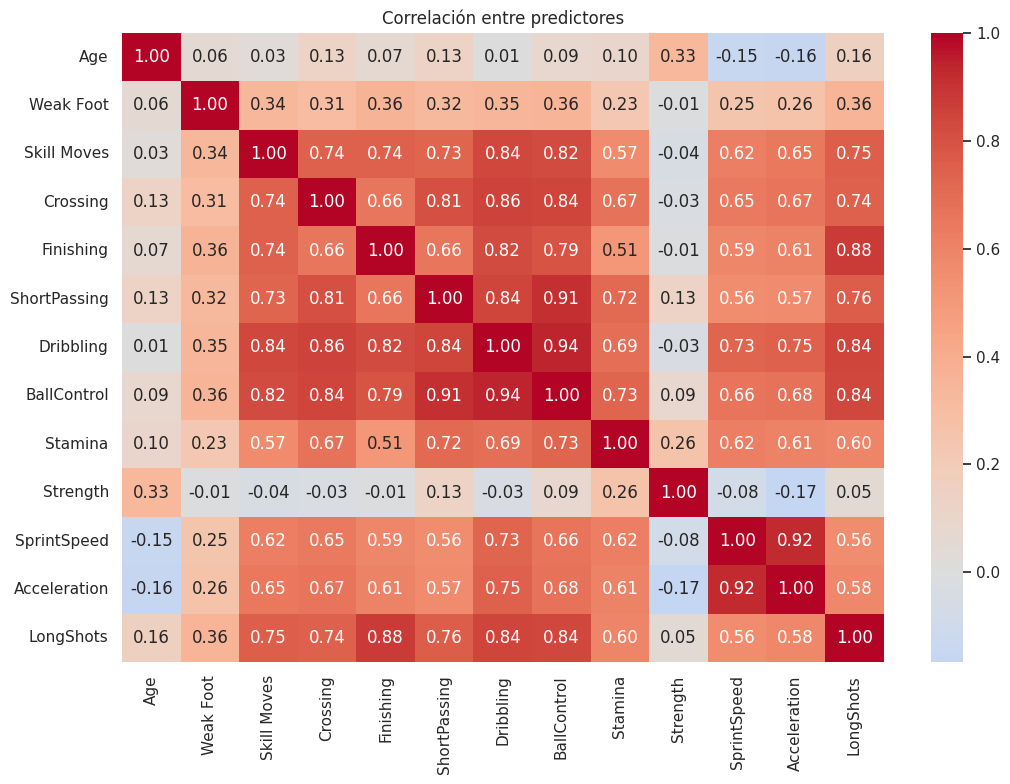

In [37]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    datos_modelo[predictores].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlación entre predictores")
plt.tight_layout()
plt.show()

**VIF**

In [39]:
from statsmodels.tools.tools import add_constant

X_vif = add_constant(
    datos_modelo[predictores].astype(float)
)

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif = vif[vif["Variable"] != "const"]

display(vif.sort_values("VIF", ascending=False))

,Variable,VIF
8,BallControl,16.219742
7,Dribbling,15.221973
12,Acceleration,8.005383
11,SprintSpeed,7.227458
6,ShortPassing,7.107907
13,LongShots,6.429744
5,Finishing,5.814650
4,Crossing,4.874596
3,Skill Moves,3.663820
9,Stamina,2.940952


El VIF permite identificar variables que contienen información redundante.

Los valores superiores a 5 requieren revisión y los superiores a 10 pueden indicar multicolinealidad importante.

Se revisará especialmente la relación entre atributos técnicos similares, como Dribbling y BallControl, o entre SprintSpeed y Acceleration.

La decisión de eliminar variables debe basarse en los valores obtenidos y no solamente en sus nombres.

**Selección definitiva y entrenamiento**

In [41]:
# Selección inicial para reducir redundancia.
# Revisar el VIF antes de mantener esta decisión.

predictores_finales = [
    "Age", "Weak Foot", "Skill Moves",
    "Crossing", "Finishing", "ShortPassing",
    "Dribbling", "Stamina", "Strength",
    "SprintSpeed", "LongShots"
]

X = datos_modelo[predictores_finales]
y = datos_modelo["Overall"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo_fifa = LinearRegression()
modelo_fifa.fit(X_train, y_train)

pred_train = modelo_fifa.predict(X_train)
pred_test = modelo_fifa.predict(X_test)

**métricas**

In [42]:
def evaluar(y_real, y_pred):
    return {
        "R²": r2_score(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred))
    }

metricas_fifa = pd.DataFrame({
    "Entrenamiento": evaluar(y_train, pred_train),
    "Prueba": evaluar(y_test, pred_test)
}).T

display(metricas_fifa.round(4))

,R²,MAE,RMSE
Entrenamiento,0.4728,3.8756,5.0318
Prueba,0.4451,3.9246,5.0833


**coeficientes**

In [43]:
coeficientes = pd.DataFrame({
    "Variable": predictores_finales,
    "Coeficiente": modelo_fifa.coef_
})

display(coeficientes.sort_values("Coeficiente", ascending=False))

print("Intercepto:", modelo_fifa.intercept_)

,Variable,Coeficiente
2,Skill Moves,2.674183
0,Age,0.495347
1,Weak Foot,0.416185
5,ShortPassing,0.196984
8,Strength,0.122494
9,SprintSpeed,0.043097
10,LongShots,0.032526
3,Crossing,-0.007295
4,Finishing,-0.029127
7,Stamina,-0.046885


Intercepto: 31.485438304510716


Se interpretarán al menos tres coeficientes del modelo.

- Age: representa el cambio estimado en puntos de Overall por cada año adicional de edad, manteniendo constantes los demás predictores.
- Finishing: representa el cambio estimado en Overall por cada punto adicional en la capacidad de finalización.
- Strength: representa el cambio estimado en Overall por cada punto adicional de fuerza.

Los coeficientes pueden ser positivos o negativos y no deben interpretarse como relaciones causales.

Los valores concretos se interpretarán según la tabla obtenida.

**Visualización del modelo**

**predictor más correlacionado**

Predictor más correlacionado: ShortPassing


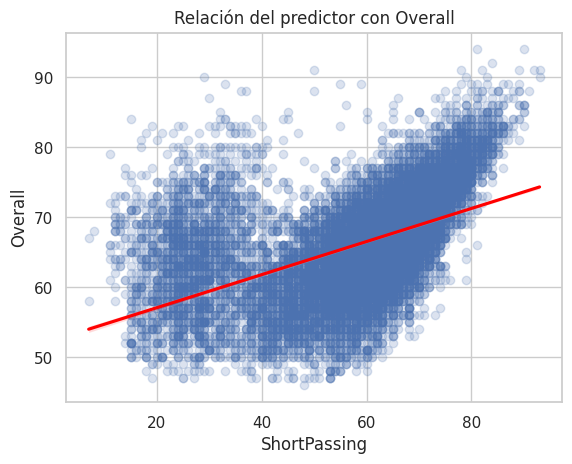

In [44]:
corr_final = (
    datos_modelo[predictores_finales + ["Overall"]]
    .corr()["Overall"]
    .drop("Overall")
)

mejor_predictor = corr_final.abs().idxmax()

print("Predictor más correlacionado:", mejor_predictor)

sns.regplot(
    data=datos_modelo,
    x=mejor_predictor,
    y="Overall",
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.title("Relación del predictor con Overall")
plt.show()

**reales vs. predichos**

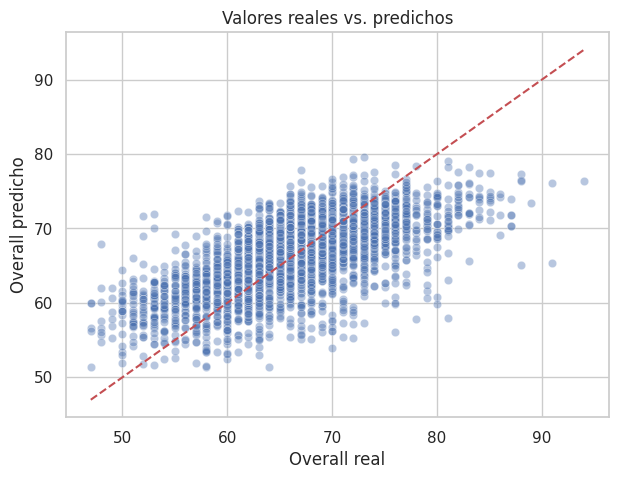

In [45]:
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_test, y=pred_test, alpha=0.4)

limites = [
    min(y_test.min(), pred_test.min()),
    max(y_test.max(), pred_test.max())
]

plt.plot(limites, limites, "r--")

plt.xlabel("Overall real")
plt.ylabel("Overall predicho")
plt.title("Valores reales vs. predichos")
plt.show()

**Heterogeneidad por posición**

In [46]:
posiciones_test = datos_modelo.loc[X_test.index, "Position"]

grupos = {
    "Porteros": posiciones_test == "GK",
    "Jugadores de campo": posiciones_test != "GK"
}

resultados_grupos = []

for nombre, mascara in grupos.items():
    if mascara.sum() >= 2:
        resultados_grupos.append({
            "Grupo": nombre,
            "Cantidad": int(mascara.sum()),
            **evaluar(y_test[mascara], pred_test[mascara])
        })

display(pd.DataFrame(resultados_grupos).round(4))

,Grupo,Cantidad,R²,MAE,RMSE
0,Porteros,394,-0.1607,6.1952,7.7721
1,Jugadores de campo,3235,0.5261,3.6481,4.6508


Se comparó el rendimiento del modelo entre porteros y jugadores de campo.

Esta separación permite comprobar si el modelo tiene un comportamiento similar en ambos grupos.

Si las métricas presentan diferencias importantes, significa que el rendimiento global podría estar ocultando errores específicos de algunas posiciones.

# Bloque 3. Regresión lineal con dataset propio

En este bloque se aplicará el proceso de regresión lineal al dataset Netflix Movies and TV Shows.

El objetivo será predecir la duración de las películas en minutos utilizando características disponibles en el dataset.

Se analizarán las distribuciones, las correlaciones, los errores y las posibles diferencias entre grupos de películas.

**Descarga y carga**

In [47]:
carpeta_netflix = Path(
    kagglehub.dataset_download("shivamb/netflix-shows")
)

print("Archivos disponibles:")

for archivo in carpeta_netflix.rglob("*"):
    if archivo.is_file():
        print(archivo.name)

100%|██████████| 1.34M/1.34M [00:00<00:00, 101MB/s]

Extracting files...
Archivos disponibles:
netflix_titles.csv


In [48]:
df_netflix = pd.read_csv(
    carpeta_netflix / "netflix_titles.csv"
)

print("Dimensiones:", df_netflix.shape)
display(df_netflix.head())

Dimensiones: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [49]:
df_netflix.info()

print("Valores nulos:")
display(df_netflix.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
Valores nulos:


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


**Preparación de datos**

In [50]:
peliculas = df_netflix[
    df_netflix["type"] == "Movie"
].copy()

peliculas["duration_min"] = pd.to_numeric(
    peliculas["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

peliculas["description_length"] = (
    peliculas["description"].fillna("").str.len()
)

peliculas["cast_count"] = peliculas["cast"].apply(
    lambda x: len(x.split(",")) if pd.notna(x) else 0
)

columnas = [
    "duration_min",
    "release_year",
    "description_length",
    "cast_count",
    "rating"
]

peliculas = peliculas[columnas].dropna().copy()

print("Películas disponibles:", len(peliculas))
display(peliculas.head())

Películas disponibles: 6126


,duration_min,release_year,description_length,cast_count,rating
0,90.0,2020,152,0,PG-13
6,91.0,2021,153,10,PG
7,125.0,1993,151,8,TV-MA
9,104.0,2021,151,11,PG-13
12,127.0,2021,141,11,TV-MA


Se seleccionaron únicamente películas porque las series utilizan temporadas como medida de duración.

Se convirtió la duración a minutos y se crearon dos variables numéricas: cantidad de actores registrados y longitud de la descripción.

Se eliminaron los registros incompletos en las variables seleccionadas.

Estas variables permiten construir un modelo de regresión sencillo, aunque no necesariamente tendrán una relación fuerte con la duración.

**EDA**

**histogramas**

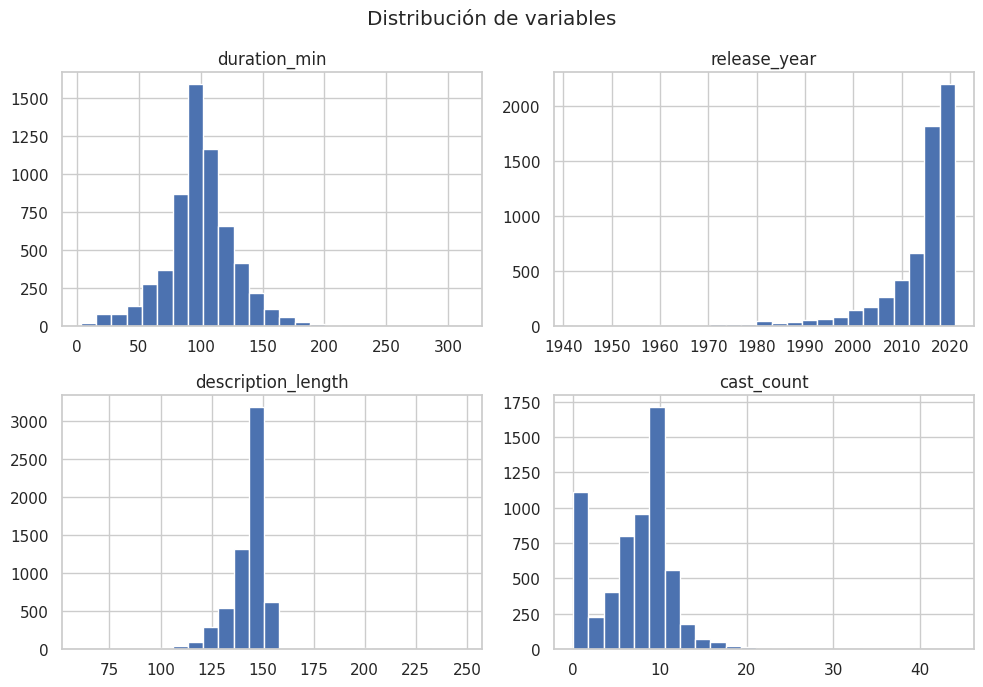

In [51]:
variables = [
    "duration_min",
    "release_year",
    "description_length",
    "cast_count"
]

peliculas[variables].hist(figsize=(10, 7), bins=25)

plt.suptitle("Distribución de variables")
plt.tight_layout()
plt.show()

**box-plots**

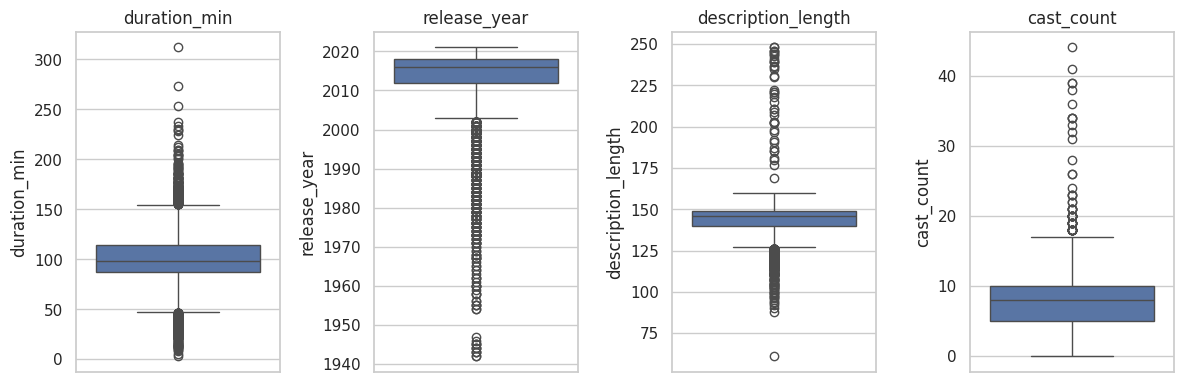

In [52]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for ax, columna in zip(axes, variables):
    sns.boxplot(y=peliculas[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

**correlaciones**

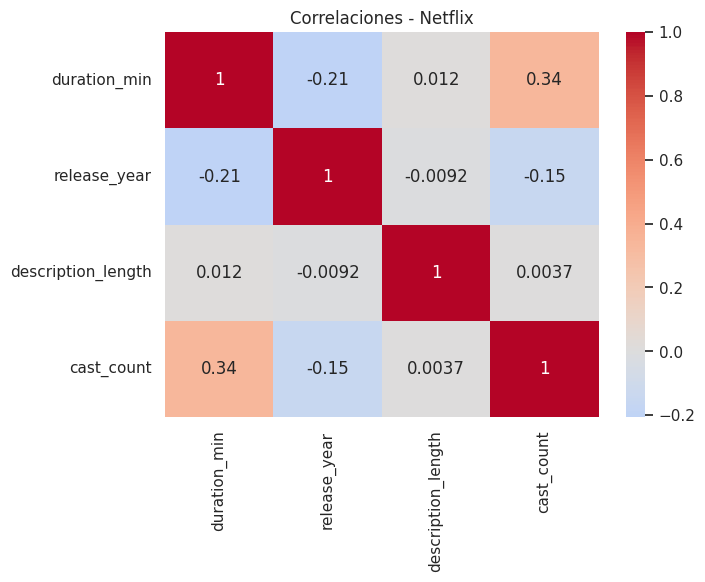

In [53]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    peliculas[variables].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Correlaciones - Netflix")
plt.show()

Se revisó la distribución de la duración de las películas y su relación con el año de lanzamiento, la cantidad de actores registrados y la longitud de la descripción.

La matriz de correlaciones permite identificar cuáles de estas variables presentan mayor asociación lineal con la duración.

Las correlaciones se utilizarán como apoyo para interpretar el modelo, sin asumir que una variable causa cambios en otra.

**Selección de predictores**

In [54]:
predictores_netflix = [
    "release_year",
    "description_length",
    "cast_count"
]

X_netflix = peliculas[predictores_netflix]
y_netflix = peliculas["duration_min"]

display(X_netflix.head())

,release_year,description_length,cast_count
0,2020,152,0
6,2021,153,10
7,1993,151,8
9,2021,151,11
12,2021,141,11


Se utilizaron el año de lanzamiento, la longitud de la descripción y la cantidad de actores registrados.

Estas variables no se calculan directamente a partir de la duración, por lo que no presentan una fuga matemática evidente de la variable objetivo.

Sin embargo, la información de la descripción y del reparto puede no estar disponible para todos los títulos antes de su publicación. Por lo tanto, el modelo se considera un ejercicio académico de análisis y no un sistema de predicción de películas futuras.

**Multicolinealidad**

In [55]:
X_vif_netflix = add_constant(X_netflix.astype(float))

vif_netflix = pd.DataFrame({
    "Variable": X_vif_netflix.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_netflix.values, i
        )
        for i in range(X_vif_netflix.shape[1])
    ]
})

display(
    vif_netflix[
        vif_netflix["Variable"] != "const"
    ].round(3)
)

,Variable,VIF
1,release_year,1.023
2,description_length,1.000
3,cast_count,1.023


Se utilizó el VIF para comprobar si los predictores presentan información redundante.

Si los valores son bajos, no existe evidencia importante de multicolinealidad.

Los valores altos requieren revisar si algunas variables aportan información demasiado similar.

**Entrenamiento**

In [57]:
Xn_train, Xn_test, yn_train, yn_test = train_test_split(
    X_netflix,
    y_netflix,
    test_size=0.2,
    random_state=42
)

modelo_netflix = LinearRegression()
modelo_netflix.fit(Xn_train, yn_train)

predn_train = modelo_netflix.predict(Xn_train)
predn_test = modelo_netflix.predict(Xn_test)

**métricas**

In [58]:
metricas_netflix = pd.DataFrame({
    "Entrenamiento": evaluar(yn_train, predn_train),
    "Prueba": evaluar(yn_test, predn_test)
}).T

display(metricas_netflix.round(4))

,R²,MAE,RMSE
Entrenamiento,0.1386,19.3760,26.5905
Prueba,0.1395,18.3375,24.8149


**coeficientes**

In [59]:
coef_netflix = pd.DataFrame({
    "Variable": predictores_netflix,
    "Coeficiente": modelo_netflix.coef_
})

display(coef_netflix)

print("Intercepto:", modelo_netflix.intercept_)

,Variable,Coeficiente
0,release_year,-0.490377
1,description_length,0.032692
2,cast_count,2.064430


Intercepto: 1067.0573994242882


**Visualizaciones del modelo**

**recta de regresión**

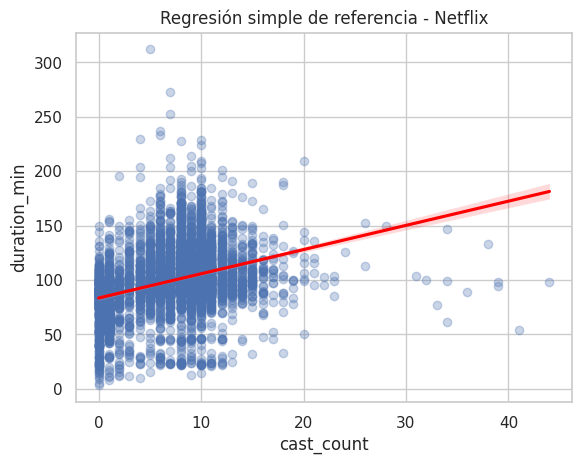

In [60]:
corr_netflix = (
    peliculas[variables]
    .corr()["duration_min"]
    .drop("duration_min")
)

mejor_n = corr_netflix.abs().idxmax()

sns.regplot(
    data=peliculas,
    x=mejor_n,
    y="duration_min",
    line_kws={"color": "red"},
    scatter_kws={"alpha": 0.3}
)

plt.title("Regresión simple de referencia - Netflix")
plt.show()

**residuos**

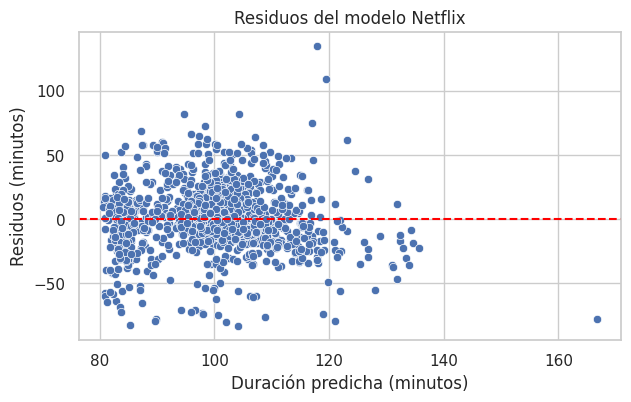

In [61]:
residuos_netflix = yn_test - predn_test

plt.figure(figsize=(7, 4))

sns.scatterplot(
    x=predn_test,
    y=residuos_netflix
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Duración predicha (minutos)")
plt.ylabel("Residuos (minutos)")
plt.title("Residuos del modelo Netflix")
plt.show()

**Heterogeneidad por clasificación**

In [62]:
rating_test = peliculas.loc[Xn_test.index, "rating"]

grupo1 = rating_test == "TV-MA"
grupo2 = rating_test != "TV-MA"

resultados = []

for nombre, mascara in {
    "TV-MA": grupo1,
    "Otras clasificaciones": grupo2
}.items():

    if mascara.sum() >= 2:
        resultados.append({
            "Grupo": nombre,
            "Cantidad": int(mascara.sum()),
            **evaluar(
                yn_test[mascara],
                predn_test[mascara]
            )
        })

display(pd.DataFrame(resultados).round(4))

,Grupo,Cantidad,R²,MAE,RMSE
0,TV-MA,409,0.1842,15.0382,19.8909
1,Otras clasificaciones,817,0.1115,19.9892,26.9441


Se comparó el error de predicción entre películas clasificadas TV-MA y películas con otras clasificaciones.

Esta comparación permite identificar si el modelo funciona de manera diferente según el tipo de audiencia.

Las diferencias se evaluarán considerando las métricas de cada grupo y su cantidad de registros.

# Preguntas de cierre

**1. Interpretación de un coeficiente**

El coeficiente de `release_year` indica el cambio estimado en la duración de una película, medido en minutos, por cada año adicional de lanzamiento, manteniendo constantes las demás variables.

Según el resultado obtenido, se debe indicar si la relación es positiva o negativa y cuánto cambia la duración estimada.

**2. Comparación entre entrenamiento y prueba**

Se compararon las métricas de entrenamiento y prueba para evaluar si el modelo mantiene un rendimiento similar con datos no utilizados durante el ajuste.

Una diferencia considerable entre ambos conjuntos podría indicar problemas de generalización.

**3. Supuesto de regresión lineal**

Se analizó el gráfico de residuos para comprobar si existe algún patrón sistemático.

Si los residuos se distribuyen alrededor de cero sin una estructura clara, esto es compatible con una relación lineal adecuada. Si aparecen curvas o patrones, puede indicar que el modelo no representa correctamente las relaciones entre las variables.

# Conclusiones generales

En esta actividad se aplicaron modelos de regresión lineal simple y múltiple utilizando tres datasets diferentes.

En el primer bloque se estudió la relación entre las mediciones de células. En el segundo se analizaron características de jugadores de FIFA 19 y su valoración general. Finalmente, se aplicó el procedimiento a un dataset de películas de Netflix.

Se utilizaron métricas como R², MAE y RMSE, además de gráficos de correlación y residuos, para evaluar el comportamiento de los modelos.

También se revisaron problemas como la fuga de datos, la multicolinealidad y la heterogeneidad.

La actividad permitió comprender que un modelo no debe evaluarse solamente por sus métricas, sino también por la calidad de sus variables, sus supuestos y su capacidad para trabajar con datos no utilizados durante el entrenamiento.